# Week 7 — Exercise 2: From a protein table to biology

**27200 Data-driven Bioengineering**

At the end of a proteomics experiment you receive a table: one row per protein, one column per sample,
filled with intensities. A very common situation is to have that table and not know what to do with
it. This exercise has two parts:

| Part | Data | What you do |
|---|---|---|
| A | A benchmark where the right answer is known | Go through filtering, log transformation, missing values, normalization, imputation and testing, and see what each choice does to the result |
| B | A real experiment: what happens when a kidney cell loses the tumour suppressor FLCN | t-test, multiple testing correction, volcano plot, then enrichment and pathway analysis to find out what the changing proteins *do* |

## Part A — A benchmark with a known answer

Normally you cannot check whether your analysis is right, because you do not know the true answer.
Here you can. The data is a benchmark
([Cox et al. 2014](https://doi.org/10.1074/mcp.M113.031591), PRIDE
[PXD000279](https://www.ebi.ac.uk/pride/archive/projects/PXD000279)):

- **HeLa lysate** (human) mixed with **E. coli lysate**
- two conditions, **L** and **H**, three replicates each
- the amount of HeLa is the **same** in L and H
- H contains **three times more E. coli** than L

So the right answer is known: human proteins should not change (log2 ratio 0), and E. coli proteins
should all go up by a factor of 3 (log2 ratio 1.58). Every human protein you call significant is a
false positive.

In [2]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE = "https://raw.githubusercontent.com/UadKLab/27200_Data-Driven-Bioengineering/main/weeks/week07_proteomics/data/"
def fetch(name):
    '''Download a course data file once; afterwards use the local copy.'''
    if not os.path.exists(name):
        urllib.request.urlretrieve(BASE + name, name)
    return name

pg = pd.read_csv(fetch("maxlfq_hela_ecoli_proteinGroups.csv"))   # one row per protein group
print(pg.shape)
pg.head(3)

(6694, 17)


,Protein IDs,Majority protein IDs,Gene names,Fasta headers,Peptides,Razor + unique peptides,Unique peptides,Only identified by site,Reverse,Contaminant,LFQ intensity H1,LFQ intensity H2,LFQ intensity H3,LFQ intensity L1,LFQ intensity L2,LFQ intensity L3,Species
0,A0AV96;B7Z8Z7;A0AV96-2;D6R9D6;D6RBS9;D6REZ6;D6...,A0AV96;B7Z8Z7;A0AV96-2;D6R9D6,RBM47,>sp|A0AV96|RBM47_HUMAN RNA-binding protein 47 ...,13,13,13,NaN,NaN,NaN,166790000,176680000,140720000,202980000,245050000,259580000,Human
1,A0AVT1;A0AVT1-2;H0Y8S8;A0AVT1-4;A0AVT1-3,A0AVT1;A0AVT1-2,UBA6,>sp|A0AVT1|UBA6_HUMAN Ubiquitin-like modifier-...,14,14,14,NaN,NaN,NaN,34679000,46278000,24750000,72394000,71990000,58362000,Human
2,H7BXI1;A0FGR8-6;A0FGR8-2;A0FGR8;C9JGI7;A0FGR8-...,H7BXI1;A0FGR8-6;A0FGR8-2;A0FGR8;C9JGI7;A0FGR8-4,ESYT2,>tr|H7BXI1|H7BXI1_HUMAN Extended synaptotagmin...,11,11,11,NaN,NaN,NaN,56390000,55263000,58800000,85986000,101540000,91829000,Human


The table comes from MaxQuant, the search and quantification software that produced it. We kept the
columns you need:

| Column | Meaning |
|---|---|
| `Protein IDs` | all proteins that share the peptides of this row (a *protein group*) |
| `Peptides`, `Unique peptides` | how many peptides were seen |
| `Reverse` | `+` if the group is a decoy (the reversed sequences from Exercise 1) |
| `Contaminant` | `+` for common contaminants: keratin from skin, trypsin itself, serum proteins |
| `Only identified by site` | `+` if seen only through a modified peptide |
| `LFQ intensity L1 ... H3` | the label-free quantification value per sample; 0 means not measured |
| `Species` | added by us from the protein headers |

## A1 · Filter

In [ ]:
lfq = [c for c in pg.columns if c.startswith("LFQ intensity")]   # the six intensity columns
L = [c for c in lfq if c.endswith(("L1", "L2", "L3"))]          # condition L (1x E. coli)
H = [c for c in lfq if c.endswith(("H1", "H2", "H3"))]          # condition H (3x E. coli)

# Remove decoys, contaminants and groups seen only through a modified peptide
keep = (pg["Reverse"] != "+") & (pg["Contaminant"] != "+") & (pg["Only identified by site"] != "+") \
       & pg.Species.isin(["Human", "E. coli"])
print(f"removed: {(pg['Reverse'] == '+').sum()} decoys, {(pg['Contaminant'] == '+').sum()} contaminants, "
      f"{(pg['Only identified by site'] == '+').sum()} only-by-site")
d = pg[keep].copy()
print(f"kept {len(d)} protein groups:", d.Species.value_counts().to_dict())

removed: 84 decoys, 44 contaminants, 80 only-by-site
kept 6507 protein groups: {'Human': 4608, 'E. coli': 1899}


## A2 · Log-transform

Intensities span five or six orders of magnitude and are skewed, as you saw in Week 4. On the log
scale they are roughly normal, and a **fold change becomes a difference**, so a doubling and a halving
are equally far from zero (+1 and −1 in log2).

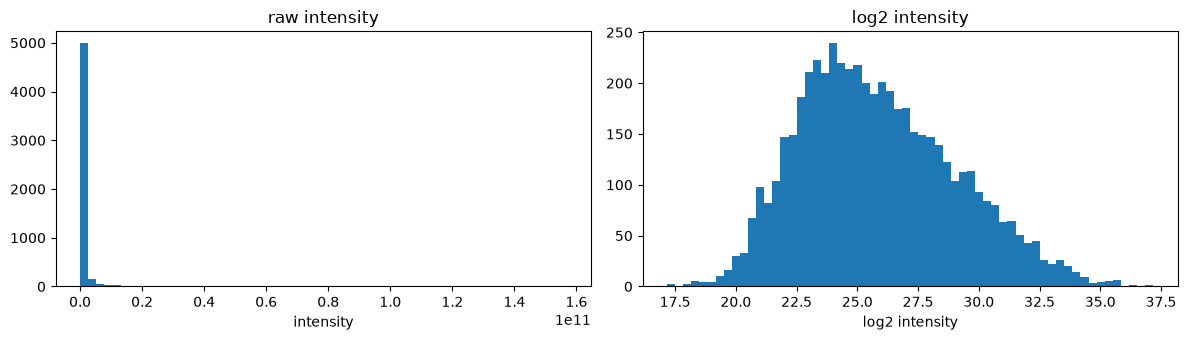

In [ ]:
X = np.log2(d[lfq].replace(0, np.nan))          # 0 means "not measured", not "zero protein": make it NaN

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(d[lfq[0]].replace(0, np.nan).dropna(), bins=60); ax[0].set(title="raw intensity", xlabel="intensity")
ax[1].hist(X[lfq[0]].dropna(), bins=60); ax[1].set(title="log2 intensity", xlabel="log2 intensity")
plt.tight_layout(); plt.show()

## A3 · Missing values

Not every protein is measured in every sample. Look at *which* ones are missing.

missing values per sample:
 LFQ intensity H1    1200
LFQ intensity H2    1045
LFQ intensity H3    1549
LFQ intensity L1    1336
LFQ intensity L2    1175
LFQ intensity L3     859 



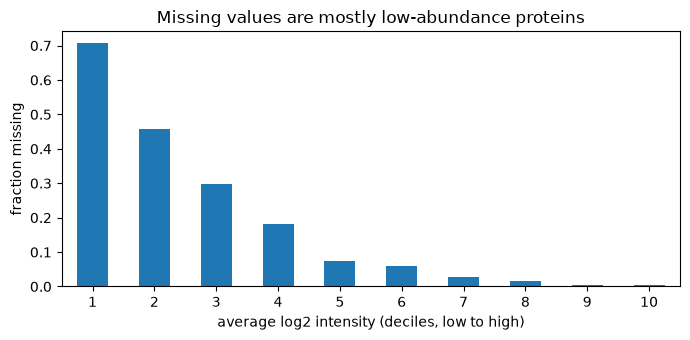

In [ ]:
print("missing values per sample:\n", X.isna().sum().to_string(), "\n")

# Split proteins into ten groups by average intensity, and ask how often each group is missing
mean_int = X.mean(axis=1)
frac_missing = X.isna().mean(axis=1)
bins = pd.qcut(mean_int, 10)
fig, ax = plt.subplots(figsize=(7, 3.5))
frac_missing.groupby(bins, observed=True).mean().plot(kind="bar", ax=ax)
ax.set(xlabel="average log2 intensity (deciles, low to high)", ylabel="fraction missing",
       title="Missing values are mostly low-abundance proteins")
ax.set_xticklabels(range(1, 11), rotation=0); plt.tight_layout(); plt.show()

Missing values are concentrated among the weakest proteins: most are missing because the protein was
**below the detection limit**, not at random. That matters for what we do about them later.

A protein measured in only one of three replicates cannot be tested fairly, so we keep proteins with
**at least 2 of 3 values in both conditions**.

In [ ]:
# notna().sum(axis=1) counts, per protein, how many samples have a value
valid = (X[L].notna().sum(axis=1) >= 2) & (X[H].notna().sum(axis=1) >= 2)
X, d = X[valid], d[valid]
print(f"{len(X)} proteins left ({d.Species.value_counts().to_dict()}), "
      f"{int(X.isna().sum().sum())} missing values remain")

5019 proteins left ({'Human': 3455, 'E. coli': 1564}), 612 missing values remain


## A4 · Normalize — and check the assumption

Samples never contain exactly the same amount of material, so intensities differ between runs for
technical reasons. **Normalization** removes that. The usual way is to shift every sample so that its
median is the same.

That rests on an assumption: **most proteins do not change between the conditions**. Is that true
here? Look at the design again before you run the next cell.

as delivered (MaxLFQ-normalized)    human median log2FC -0.51   E. coli +1.22
median-normalized, all proteins     human median log2FC -0.57   E. coli +1.15
median-normalized, human only       human median log2FC -0.07   E. coli +1.66
expected                            human median log2FC +0.00   E. coli +1.58


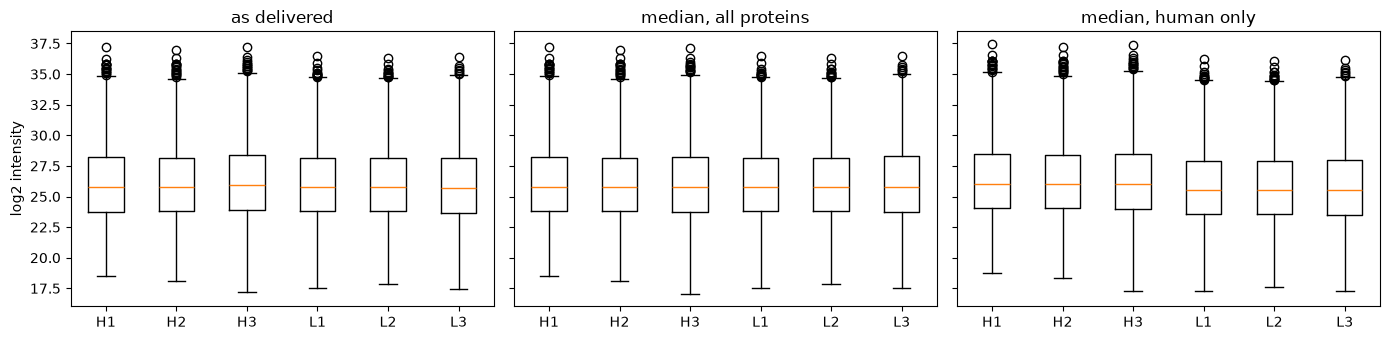

In [ ]:
def log2fc(M):
    '''log2 fold change H/L: on the log scale a ratio is a difference of means.'''
    return M[H].mean(axis=1) - M[L].mean(axis=1)

def report(M, label):
    fc = log2fc(M)
    print(f"{label:34}  human median log2FC {fc[d.Species == 'Human'].median():+.2f}   "
          f"E. coli {fc[d.Species == 'E. coli'].median():+.2f}")

human = d.Species == "Human"
# Median normalization: subtract each sample's median, then add back the average median
X_all = X - X.median() + X.median().mean()                         # medians of all proteins
X_hum = X - X[human].median() + X[human].median().mean()            # medians of the human proteins only

report(X, "as delivered (MaxLFQ-normalized)")
report(X_all, "median-normalized, all proteins")
report(X_hum, "median-normalized, human only")
print(f"{'expected':34}  human median log2FC +0.00   E. coli +{np.log2(3):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for a, M, t in zip(ax, (X, X_all, X_hum), ("as delivered", "median, all proteins", "median, human only")):
    a.boxplot([M[c].dropna() for c in lfq]); a.set_title(t)
    a.set_xticks(range(1, len(lfq) + 1)); a.set_xticklabels([c[-2:] for c in lfq])
ax[0].set_ylabel("log2 intensity"); plt.tight_layout(); plt.show()

**Question 2.1** The boxplots of the three versions look almost the same, yet the human fold changes
differ by more than half a log2 unit. Why? What fraction of the proteins in this table are E. coli, and
what happens to the median of an H sample when all of them go up?

**A:** The boxplot summarizes the growth in each sample, it doesn't distinguish between human and e coli cells. **If many E. coli grow, the median can be moved even if human proteins remain unchanged.** Median-scaled normalisation can rescale the data, making apparent a change in human proteins. Then the fraction of e. coli is calculated by: (number of e coli proteins/number of total proteins).



**Question 2.2** In a real experiment you do not know which proteins are unchanged. What could you do
instead? (Think of housekeeping proteins, spike-in standards, or asking how many proteins you expect
to change.)

**A:**
**Housekeeping proteins:** you select proteins already present in your sample that you expect to remain stable.
**Spike-in standards:** Instead of relying on a naturally occurring protein that you hope hasn't changed, you have a reference whose starting amount you control.
**Global normalization:** you dno't add anything and don't necessarily select particular proteins, instead, you calculate the median (or sth. else) by assumming that most proteins don;t change.


**A simple analogy:**
- Housekeeping proteins: compare everyone against a trusted person in the room.
- Spike-ins: bring your own calibrated measuring stick into the room.
- Global normalization: compare everyone against the average or middle of the room.
If most people in the room suddenly get taller, the third method might give you a misleading impression of how tall a particular person is.

For the rest of Part A we use the human-only normalization. Change `Xn` below to `X` or `X_all` later
and rerun Part A to see what the choice costs.

In [1]:
Xn = X_hum        # try X or X_all here

NameError: name 'X_hum' is not defined

## A5 · Impute

A t-test needs numbers. Since most missing values are *low* proteins, a common choice (from the
Perseus software) is to fill them with random values drawn from a narrow distribution near the
detection limit: shifted down by 1.8 standard deviations and 0.3 times as wide.

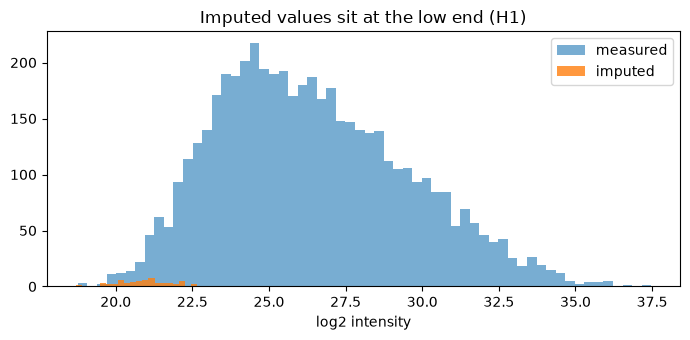

In [ ]:
rng = np.random.default_rng(0)                 # fixed seed, so everyone gets the same random values
Xi = Xn.copy()
for c in Xi.columns:                           # one sample at a time
    m, s = Xn[c].mean(), Xn[c].std()           # that sample's mean and spread
    miss = Xi[c].isna()
    Xi.loc[miss, c] = rng.normal(m - 1.8 * s, 0.3 * s, miss.sum())   # low, narrow random values

c = lfq[0]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(Xn[c].dropna(), bins=60, alpha=0.6, label="measured")
ax.hist(Xi.loc[Xn[c].isna(), c], bins=20, alpha=0.8, label="imputed")
ax.set(xlabel="log2 intensity", title=f"Imputed values sit at the low end ({c[-2:]})"); ax.legend()
plt.tight_layout(); plt.show()

## A6 · Do the samples look right?

Before testing anything, check that replicates resemble each other more than they resemble the other
condition. A principal component analysis (PCA) places each sample on the two axes along which the
samples differ most.

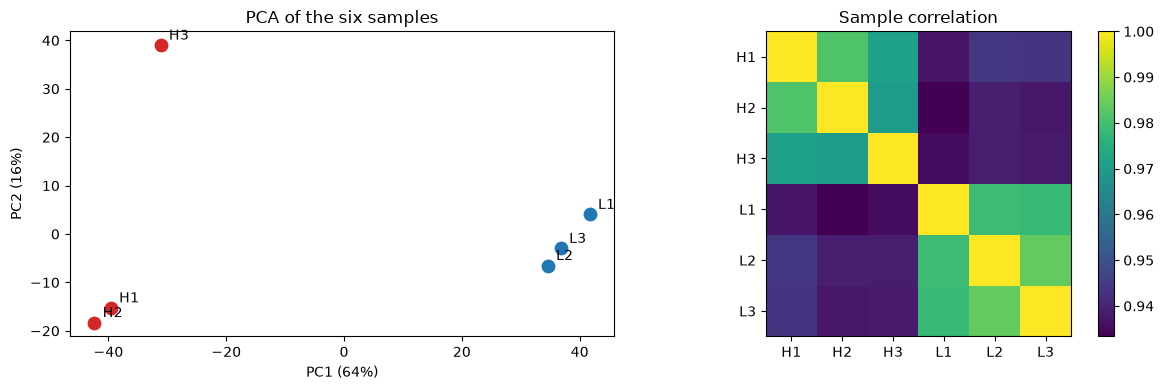

In [ ]:
Z = (Xi - Xi.mean(axis=1).values[:, None])                   # centre each protein on its own mean
u, sv, vt = np.linalg.svd(Z.values, full_matrices=False)      # singular value decomposition = PCA
pc = vt[:2].T * sv[:2]                                        # sample coordinates on PC1 and PC2
explained = sv**2 / (sv**2).sum()                             # share of the variation each PC explains

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (x, y), name in zip(pc, lfq):
    ax[0].scatter(x, y, s=80, color="tab:red" if name[-2] == "H" else "tab:blue")
    ax[0].annotate(name[-2:], (x, y), textcoords="offset points", xytext=(6, 4))
ax[0].set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})", title="PCA of the six samples")
im = ax[1].imshow(Xi.corr(), cmap="viridis"); ax[1].set_title("Sample correlation")
ax[1].set_xticks(range(6)); ax[1].set_xticklabels([c[-2:] for c in lfq])
ax[1].set_yticks(range(6)); ax[1].set_yticklabels([c[-2:] for c in lfq]); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()

## A7 · Test every protein

A two-sample t-test per protein (Welch's version, which does not assume equal variances), then the
Benjamini–Hochberg correction from Week 4, because we run one test per protein.


**Explanation:**
If a protein has an expression level of 10 in your control group and 40 in your treatment group, the fold change is 40/10=4. It has increased by a 4-fold change.

Volcano plot: used to identify changes in large data sets, **between 2 conditions.** In this case":
**-x axis:** Biological significance. How much the quantity actually changed (log2 fold change).
**-y axis:**  Statistical significance. How reliable or statistically robust that change is (-log10 of p-value).

*Low or uninteresting points satay at the bottom, while outstanding changes erutp up to the sides like a volcano.*

Negative values in log2: growth decrease ("downregulation").

X-axis (log
2 fold change): Tells you **the magnitude and direction of the change** (How much did it change? Did it increase or decrease?).

Y-axis (−log
10 p-value): Tells you **how confident you can be in that change** (Is it statistically significant, or just random noise?).

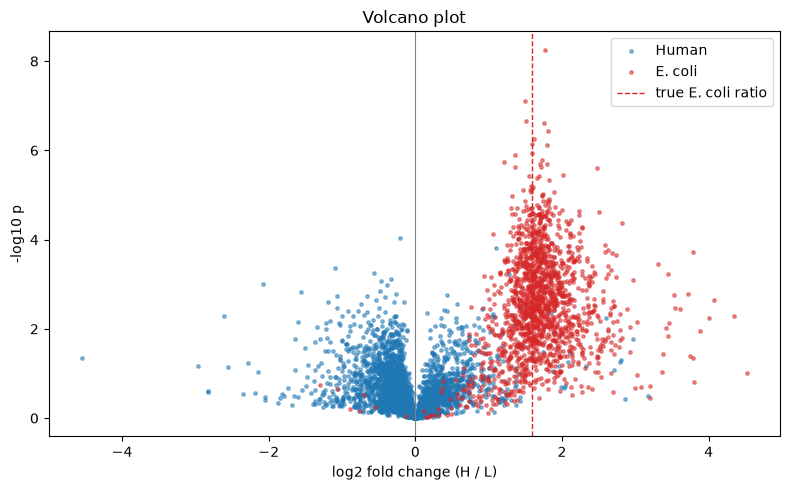

In [ ]:
# axis=1: one t-test per row (protein), comparing the three H columns with the three L columns
t = stats.ttest_ind(Xi[H], Xi[L], axis=1, equal_var=False)
res = pd.DataFrame({"gene": d["Gene names"].fillna(""), "species": d.Species,
                    "log2FC": log2fc(Xi), "p": t.pvalue})
res["q"] = stats.false_discovery_control(res.p)               # Benjamini-Hochberg adjusted p-values
res["significant"] = res.q < 0.05

fig, ax = plt.subplots(figsize=(8, 5))
for sp, col in (("Human", "tab:blue"), ("E. coli", "tab:red")):
    r = res[res.species == sp]
    ax.scatter(r.log2FC, -np.log10(r.p), s=6, alpha=0.5, color=col, label=sp)
ax.axvline(0, color="grey", lw=0.8); ax.axvline(np.log2(3), color="tab:red", ls="--", lw=1, label="true E. coli ratio")
ax.set(xlabel="log2 fold change (H / L)", ylabel="-log10 p", title="Volcano plot"); ax.legend()
plt.tight_layout(); plt.show()

## A8 · Check against the truth

Every significant E. coli protein is a true positive. Every significant human protein is a false
positive. At q < 0.05, we *claimed* that at most 5% of our significant list is wrong.

In [ ]:
def score(res, fc_cut=0.0):
    '''Count true and false positives, optionally requiring a minimum fold change.'''
    sig = res.significant & (res.log2FC.abs() >= fc_cut)
    tp = int((sig & (res.species == "E. coli")).sum()); fp = int((sig & (res.species == "Human")).sum())
    n_ecoli = int((res.species == "E. coli").sum())
    return dict(fold_change_cutoff=fc_cut, significant=tp + fp, E_coli_found=tp,
                E_coli_total=n_ecoli, human_false_positives=fp,
                actual_FDR=round(fp / max(tp + fp, 1), 3))

pd.DataFrame([score(res, c) for c in (0, 0.5, 1.0)])

,fold_change_cutoff,significant,E_coli_found,E_coli_total,human_false_positives,actual_FDR
0,0.0,1184,1076,1564,108,0.091
1,0.5,1138,1076,1564,62,0.054
2,1.0,1093,1068,1564,25,0.023


**Question 2.3** The Benjamini–Hochberg correction promises an FDR of 5%. Is the *actual* FDR
(human false positives divided by all significant proteins) below 5%? If not, which assumption behind
the test is broken? Go back to A4, set `Xn = X`, and run Part A again.

**A:** *some assumptions underlying the statistical test may not hold in the "mixed-species proteomics data". We should check whether the null distribution holds, and also the relationship between measurements.*


**Question 2.4** The human false positives that remain have small fold changes. Why does a fold-change
cutoff remove them? Is a protein that changes by 10%, with a p-value of 10⁻⁶, a false positive or a
real but unimportant change?

**A:**
**-p value:** *tells you how strong the evidemce is against the null hypothesis of "no change". It does NOT tell you how meaningful that change is.*

**-fold chance cutoff:** *removes proteins whose value is statistically meaningful but too small to meet a chosen threshold for biological relevance.*

*A change of 10% with a p-value of 10e6 can be real but not relevanto for a given situation. Because a very very small p-value tells you that the argument that its not "no change" is strong, but again, it does NOT tell you whether is meaningful or not.*

*Real but unimportant change: the protein genuinely changes, but the change is too small to be significant biologically.*

*A fold change cutoff may remove the human proteins because their apparent changes are small, but it does not mean every protein with a small change is a false positive.*


---
---
## Part B — What happens when a kidney cell loses FLCN?

**FLCN** (folliculin) is a tumour suppressor. People born with one broken copy have Birt–Hogg–Dubé
syndrome and develop kidney tumours. To find out what FLCN does,
[Glykofridis et al. (eLife, 2021)](https://doi.org/10.7554/eLife.61630) knocked it out in human renal
tubular epithelial cells and measured the proteome (PRIDE
[PXD021346](https://www.ebi.ac.uk/pride/archive/projects/PXD021346)).

The table has 12 samples, two replicates each of:

| Samples | Cells | Group we use |
|---|---|---|
| `WT_1`, `WT_2` | untouched cells | — (not used) |
| `Cas9_1`, `Cas9_2` | cells treated with CRISPR-Cas9 but no gene targeted | control |
| `TP53KO_1`, `TP53KO_2` | TP53 knocked out (needed to grow the knockout clones) | control |
| `FLCNKO_C1_…`, `C2_…`, `C3_…` | TP53 **and FLCN** knocked out: three independent clones | FLCN knockout |

So we compare **6 FLCN-knockout samples** with **4 control samples** that still have FLCN. Using three
separate clones protects against effects that belong to one clone rather than to the loss of FLCN.

*The researchers compare the proteins measured in these two groups to investigate which proteins change when FLCN is lost.*

*The three independent clones help distinguish changes associated with the knockout from changes specific to an individual clone.*

This time there is no known answer. Your job is to find out what changes, and what those changes mean.

5864 protein groups; knockout samples: 6, control samples: 4
3310 proteins measured well enough to test


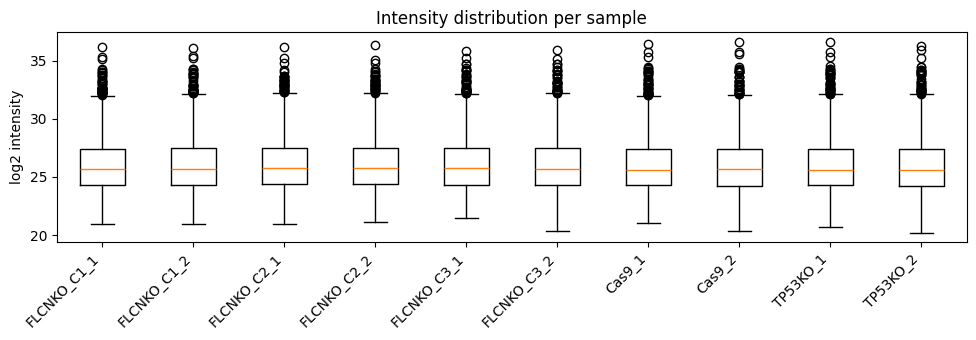

In [17]:
fl = pd.read_csv(fetch("flcn_ko_proteinGroups.csv"))
fl["gene"] = fl.gene_names.fillna("").str.split(";").str[0]     # first gene name of each protein group
ko = [c for c in fl.columns if c.startswith("LFQ FLCNKO")]      # the six knockout samples
ctl = ["LFQ Cas9_1", "LFQ Cas9_2", "LFQ TP53KO_1", "LFQ TP53KO_2"] # the four controls
print(f"{len(fl)} protein groups; knockout samples: {len(ko)}, control samples: {len(ctl)}")

# Log-transform; 0 means not measured
Y = np.log2(fl[ko + ctl].replace(0, np.nan))

# Keep proteins measured in at least 4 of 6 knockouts and 3 of 4 controls
ok = (Y[ko].notna().sum(axis=1) >= 4) & (Y[ctl].notna().sum(axis=1) >= 3) & (fl.gene != "")
Y, genes = Y[ok], fl.gene[ok]
print(f"{len(Y)} proteins measured well enough to test")

# Check that the samples are comparable: their medians should be about equal (LFQ is already normalized)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.boxplot([Y[c].dropna() for c in ko + ctl])
ax.set_xticks(range(1, 11)); ax.set_xticklabels([c[4:] for c in ko + ctl], rotation=45, ha="right")
ax.set(ylabel="log2 intensity", title="Intensity distribution per sample"); plt.tight_layout(); plt.show()

Here, unlike in Part A, most proteins are not expected to change, so the normalization assumption is
reasonable, and the medians already line up.

### B1 · t-test and multiple testing correction

We test each protein with Welch's t-test. This time we do **not** impute: we required at least 4 of 6
and 3 of 4 values, and `nan_policy="omit"` tests the values that are there.

In [18]:
t = stats.ttest_ind(Y[ko], Y[ctl], axis=1, equal_var=False, nan_policy="omit")
res_fl = pd.DataFrame({
    "gene": genes.values,
    "log2FC": (Y[ko].mean(axis=1) - Y[ctl].mean(axis=1)).values,   # knockout vs control, log2
    "p": np.asarray(t.pvalue),
})
res_fl["q"] = stats.false_discovery_control(res_fl.p)              # Benjamini-Hochberg

# Call a protein changed if q < 0.05 and it changes at least 1.5-fold (|log2FC| > 0.58) !!!!change 1.5 to 2!!!!
FC = np.log2(2)
res_fl["direction"] = np.where((res_fl.q < 0.05) & (res_fl.log2FC > FC), "up",
                       np.where((res_fl.q < 0.05) & (res_fl.log2FC < -FC), "down", "unchanged"))
print(res_fl.direction.value_counts().to_string())
res_fl.sort_values("q").head(10)

direction
unchanged    3166
up             97
down           47


,gene,log2FC,p,q,direction
959,ASAH1,3.172711,1.601136e-07,0.000265,up
1043,TUBA4A,-1.593928,1.057102e-07,0.000265,down
192,DDX21,-0.805982,6.975796e-07,0.000462,unchanged
37,RPS27A,-0.521034,6.031901e-07,0.000462,unchanged
252,FHL2,-0.589633,4.473218e-07,0.000462,unchanged
360,IMPDH2,-0.545646,9.266399e-07,0.000511,unchanged
367,ITGB3,-0.944362,2.086590e-06,0.000987,unchanged
1701,CASP3,-0.622991,3.177761e-06,0.001315,unchanged
1653,TPP1,1.415613,3.990491e-06,0.001468,up
310,HKDC1,1.311647,5.052088e-06,0.001672,up


### B2 · Volcano plot

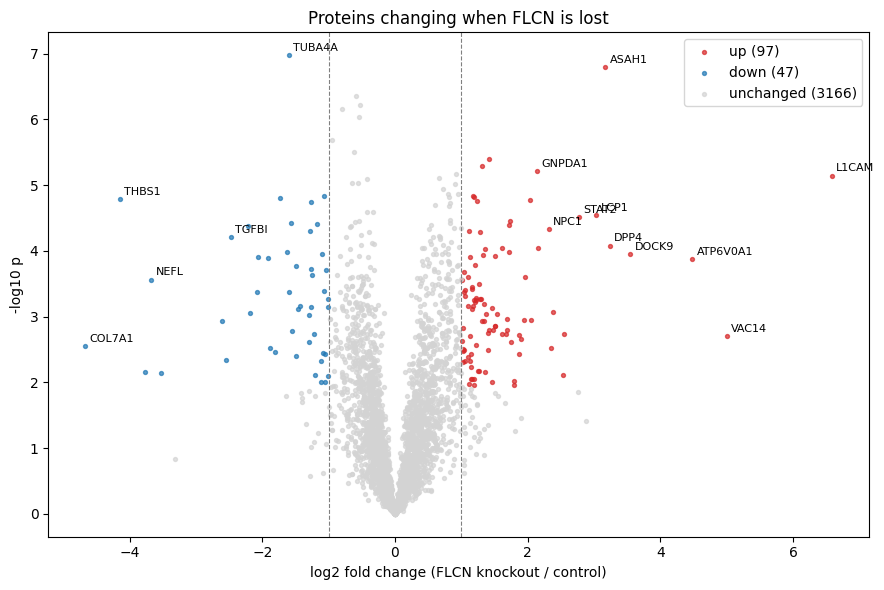

In [19]:
colors = {"up": "tab:red", "down": "tab:blue", "unchanged": "lightgrey"}
fig, ax = plt.subplots(figsize=(9, 6))
for direction, col in colors.items():
    r = res_fl[res_fl.direction == direction]
    ax.scatter(r.log2FC, -np.log10(r.p), s=8, color=col, label=f"{direction} ({len(r)})", alpha=0.7)

# Label the strongest changes: far out on both axes
top = res_fl[res_fl.direction != "unchanged"].assign(score=lambda d: -np.log10(d.p) * d.log2FC.abs())
for r in top.nlargest(15, "score").itertuples():
    ax.annotate(r.gene, (r.log2FC, -np.log10(r.p)), fontsize=8, xytext=(3, 3), textcoords="offset points")

ax.axvline(FC, color="grey", ls="--", lw=0.8); ax.axvline(-FC, color="grey", ls="--", lw=0.8)
ax.set(xlabel="log2 fold change (FLCN knockout / control)", ylabel="-log10 p",
       title="Proteins changing when FLCN is lost"); ax.legend()
plt.tight_layout(); plt.show()

**Question 2.5** Look at the labelled proteins. Do you recognize any of them? Search two or three in
[UniProt](https://www.uniprot.org). Which cellular compartment do several of them belong to?

DPP4: dipeptidyl transferase

NPC1: NPC intracellular cholesterol transporter

GNPDA1: glucoasmine-6-phosphate deaminase

TGFB1: transforming growth factor

NEFL: neurofilament light polypeptide

CO7A1: collagen alpha 1

*They belong to the extracellular space.*

### B3 · Enrichment analysis with g:Profiler

A list of 200 proteins is hard to interpret one by one. **Enrichment analysis** asks: are proteins with
a given function (a Gene Ontology term, a pathway) **over-represented** in my list, compared with what
I would expect by chance?

The comparison needs a **background**: the set of proteins that *could* have ended up in the list.
That is not the whole genome. A mass spectrometer sees only the most abundant proteins of a cell, so
the right background is **the proteins we actually measured and tested**.

[g:Profiler](https://biit.cs.ut.ee/gprofiler/) runs the test against several databases at once:
Gene Ontology (GO:BP biological process, GO:CC cellular component), Reactome (REAC) and KEGG. Its
p-values are already corrected for testing many terms.

In [20]:
!pip install -q gprofiler-official

In [26]:
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)

up = res_fl[res_fl.direction == "down"].gene.tolist()          # proteins up in the knockout !!!!(put "down" here?)!!!!
background = res_fl.gene.tolist()                             # every protein we tested

enr = gp.profile(organism="hsapiens", query=up,
                 background=background, domain_scope="custom",   # use OUR background, not the genome
                 sources=["GO:BP", "GO:CC", "REAC", "KEGG"])
print(f"{len(up)} up-regulated proteins -> {len(enr)} enriched terms")
enr[["source", "name", "p_value", "intersection_size", "term_size"]].head(15)

47 up-regulated proteins -> 11 enriched terms


,source,name,p_value,intersection_size,term_size
0,GO:CC,external encapsulating structure,0.000472,8,35
1,GO:CC,extracellular matrix,0.000472,8,35
2,GO:CC,complex of collagen trimers,0.001396,4,4
3,REAC,Extracellular matrix organization,0.004619,9,64
4,REAC,Collagen chain trimerization,0.006910,4,5
5,REAC,Anchoring fibril formation,0.006910,4,5
6,GO:BP,cell adhesion,0.009607,16,277
7,REAC,Assembly of collagen fibrils and other multime...,0.020176,5,13
8,KEGG,Integrin signaling,0.037291,7,41
9,REAC,Laminin interactions,0.046153,5,15


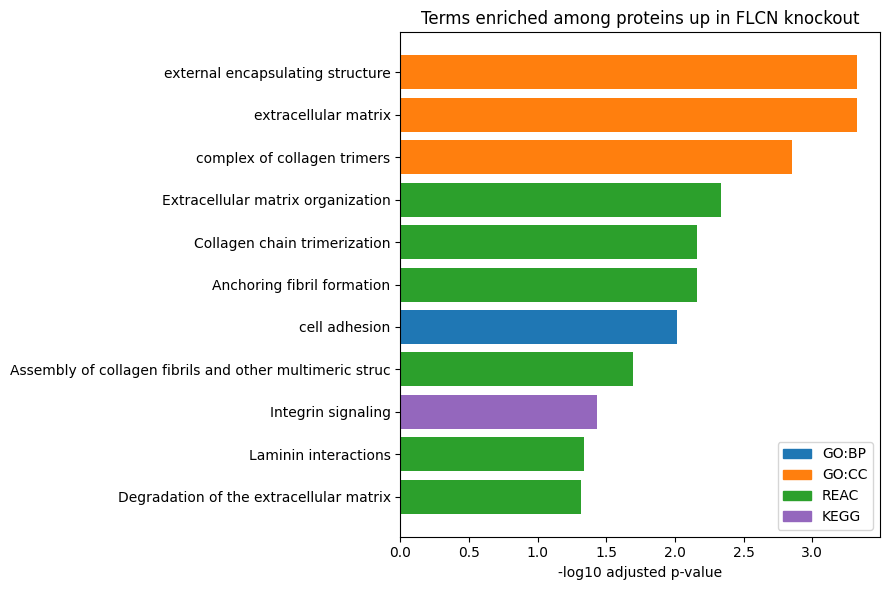

In [27]:
# Plot the 15 most significant terms; colour by database
top_terms = enr.head(15).iloc[::-1]                           # reverse so the best is on top
palette = {"GO:BP": "tab:blue", "GO:CC": "tab:orange", "REAC": "tab:green", "KEGG": "tab:purple"}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_terms.name.str[:55], -np.log10(top_terms.p_value), color=top_terms.source.map(palette))
from matplotlib.patches import Patch                          # coloured squares for the legend
ax.legend(handles=[Patch(color=col, label=src) for src, col in palette.items()], loc="lower right")
ax.set(xlabel="-log10 adjusted p-value", title="Terms enriched among proteins up in FLCN knockout")
plt.tight_layout(); plt.show()

Now repeat the analysis the way it is often (wrongly) done: against the **whole genome** as background.

In [23]:
enr_genome = gp.profile(organism="hsapiens", query=up, sources=["GO:BP", "GO:CC", "REAC", "KEGG"])
print(f"against the whole genome: {len(enr_genome)} enriched terms. The top ten:")
enr_genome[["source", "name", "p_value", "intersection_size", "term_size"]].head(10)

against the whole genome: 95 enriched terms. The top ten:


,source,name,p_value,intersection_size,term_size
0,GO:CC,vesicle,1.931397e-12,50,4032
1,GO:CC,cytoplasm,1.069955e-11,85,12601
2,GO:CC,extracellular exosome,5.368850e-11,35,2111
3,GO:CC,extracellular vesicle,8.134300e-11,35,2141
4,GO:CC,extracellular organelle,8.246720e-11,35,2142
5,GO:CC,extracellular membrane-bounded organelle,8.246720e-11,35,2142
6,GO:CC,cytoplasmic vesicle,1.215744e-08,35,2548
7,GO:CC,intracellular vesicle,1.327651e-08,35,2556
8,GO:CC,extracellular space,3.389590e-08,39,3252
9,GO:CC,vacuole,1.318315e-07,20,882


**Question 2.6** Compare the two results. Why does the whole-genome background give many more terms,
and why are they so general ("vesicle", "extracellular exosome", "cytoplasm")? Which result would you
trust, and why?

### B4 · Pathways with Reactome

[Reactome](https://reactome.org) is a curated database of biological pathways. Its analysis service
takes a list of genes and returns the pathways that are over-represented, and it gives a link where
you can see your proteins drawn on the pathway diagrams.

In [24]:
import requests

# Send the gene list to the Reactome analysis service (one gene per line)
url = "https://reactome.org/AnalysisService/identifiers/projection?pageSize=15&page=1&interactors=false"
reply = requests.post(url, data="\n".join(up), headers={"Content-Type": "text/plain"}, timeout=120).json()

paths = pd.DataFrame([{"pathway": p["name"],
                       "FDR": p["entities"]["fdr"],                    # corrected for testing many pathways
                       "found": p["entities"]["found"],                # our proteins in the pathway
                       "pathway size": p["entities"]["total"]}
                      for p in reply["pathways"]])
token = reply["summary"]["token"]
print("Open the result in Reactome's browser:")
print(f"https://reactome.org/PathwayBrowser/#/DTAB=AN&ANALYSIS={token}\n")
paths.head(10)

Open the result in Reactome's browser:
https://reactome.org/PathwayBrowser/#/DTAB=AN&ANALYSIS=MjAyNjEwMjgxNzM1MjlfNTc4NQ%3D%3D



,pathway,FDR,found,pathway size
0,Cytokine Signaling in Immune system,0.000002,32,1197
1,Interleukin-12 family signaling,0.000399,8,96
2,Signaling by Interleukins,0.000399,19,646
3,Gene and protein expression by JAK-STAT signal...,0.000496,7,73
4,Regulation of MITF-M-dependent genes involved ...,0.000564,5,28
5,Interferon Signaling,0.000642,16,511
6,Interleukin-12 signaling,0.000698,7,84
7,Interferon alpha/beta signaling,0.001145,8,129
8,Immune System,0.002615,45,3040
9,NFE2L2 regulating anti-oxidant/detoxification ...,0.024286,4,40


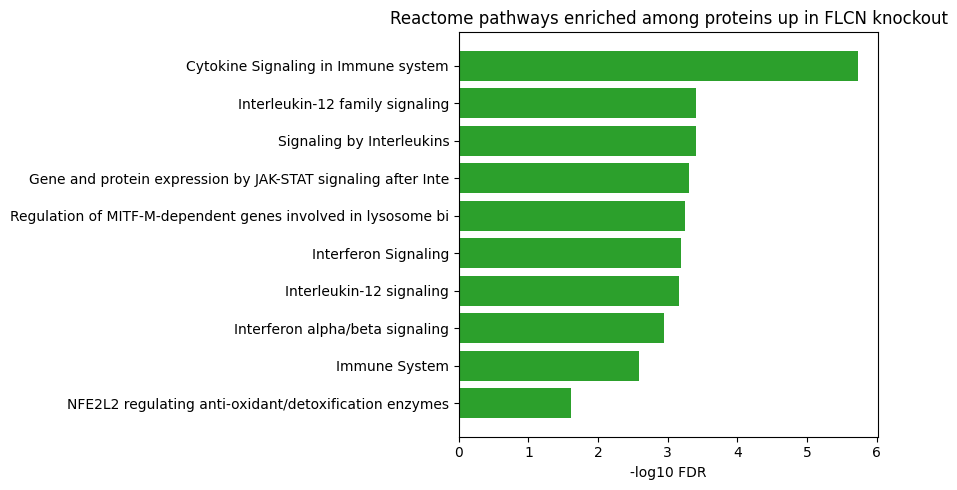

In [25]:
p = paths.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(p.pathway.str[:60], -np.log10(p.FDR), color="tab:green")
ax.set(xlabel="-log10 FDR", title="Reactome pathways enriched among proteins up in FLCN knockout")
plt.tight_layout(); plt.show()

**Question 2.7** The top Reactome pathway involves **MITF**, a transcription factor of the MiT/TFE
family. TFE3, another member of that family, is held outside the nucleus by FLCN. Using the enriched
terms, describe in two sentences what you think happens in a cell that loses FLCN. Then read the
[abstract of the paper](https://doi.org/10.7554/eLife.61630) and compare.

*If TFE3 is held by FLCN, then I think the cell doesn't replicate well because it cannot retain well the replication factors.*

*The paper says that FLCN recruits a tumor supressor, so it might slow cell proliferation axtually*.

**Question 2.8** Repeat B3 and B4 with the **down**-regulated proteins. Does a story emerge?

**Question 2.9** Your conclusions depend on the cutoffs (q < 0.05, 1.5-fold). Change the fold-change
cutoff to 2 and rerun B1–B4. Which results survive?

---
## What to take away

1. Every step — filtering, normalization, imputation, the test, the cutoff — is a choice, and each
   choice changes the list of "significant" proteins.
2. Normalization assumes that most proteins do not change. When that is false, normalization
   *creates* differences that are not there.
3. A corrected p-value controls false positives only if the model behind it is right. Check your
   assumptions on data where you know the answer, before trusting them on data where you do not.
4. Enrichment analysis turns a list of proteins into a biological statement, and the **background**
   decides what that statement is. For proteomics, the background is what you measured.